# 06 · 稳定性、SQL 核对与业务决策

本页读取已经运行完成的独立扩展产物，不重训、不根据测试结果更换模型。原验证集选择仍为 `propensity`，最佳 uplift 候选为 S-Logistic。

稳定性研究从 80 万开发行重新划分，排除旧测试集 20 万行；这不能抹去此前已看过测试结果的分析者知识，因此它是后续开发诊断，不能包装成全新独立确认。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'criteo_uplift').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from criteo_uplift.runtime import configure_runtime
configure_runtime()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from criteo_uplift.pipeline_io import result_directory
FIG = ROOT/'artifacts/extension_figures'
FIG.mkdir(exist_ok=True)


In [2]:
ST=result_directory('stability_v1', ROOT)
report=json.loads((ST/'report.json').read_text())
long=pd.read_csv(ST/'longmetrics.csv')
agg=pd.read_csv(ST/'aggregate.csv')
audit=pd.read_csv(ST/'split_audit.csv')
display({k:report[k] for k in ['experiments','fitted_models','development_n','old_test_n_excluded','all_old_test_row_overlaps_zero','all_group_split_feature_overlaps_zero']})
display(audit)
cols=['split_method','training_fraction','policy','incremental_per_100k_mean','incremental_per_100k_std','vs_propensity_per_100k_mean','train_control_events_min','train_control_events_max']
display(agg[cols])

{'experiments': 12,
 'fitted_models': 48,
 'development_n': 800000,
 'old_test_n_excluded': 200000,
 'all_old_test_row_overlaps_zero': True,
 'all_group_split_feature_overlaps_zero': True}

,seed,split_method,training_fraction,train_n,train_control_n,train_treatment_n,train_control_events,train_treatment_events,validation_n,validation_control_n,...,full_train_n,validation_fraction_of_development,assignment_probability,train_row_ids_sha256,validation_row_ids_sha256,row_overlap,train_old_test_overlap,validation_old_test_overlap,feature_group_overlap,validation_fraction_matching_train_features
0,17,row_stratified,0.25,149999,22438,127561,41,391,200000,29917,...,600000,0.250000,0.850410,ba59f6db9e1f739b5ef9095ee64c3b5e307dc1ec57940c...,1fa1308396afd1643ade81e0b1f75d0b0a0fdd063f3b8d...,0,0,0,938,0.004740
1,17,row_stratified,0.50,299999,44877,255122,82,782,200000,29917,...,600000,0.250000,0.850410,7047c88f76e96a8291b19cd6fa36f36f7ad3f39fabb2cc...,1fa1308396afd1643ade81e0b1f75d0b0a0fdd063f3b8d...,0,0,0,1857,0.009390
2,17,row_stratified,1.00,600000,89754,510246,164,1565,200000,29917,...,600000,0.250000,0.850410,403a666db7141dd8d2971f8fc46da7818be1c3e1c2388d...,1fa1308396afd1643ade81e0b1f75d0b0a0fdd063f3b8d...,0,0,0,3677,0.018610
3,17,feature_group,1.00,599941,89575,510366,169,1558,200059,30096,...,599941,0.250074,0.850694,4d11133d1c133fbfa6549dc1b76e6daf3c20071c656e88...,2355c3fbb57bf09f309a5e90b2b133e7c23f34e5437bcd...,0,0,0,0,0.000000
4,29,row_stratified,0.25,149999,22438,127561,41,391,200000,29917,...,600000,0.250000,0.850410,4869b98b4bd5fc6688ba788ab1b443c0522920c0d35054...,433fdc69a27b8589f818ec9230c6867a777e93d114da92...,0,0,0,941,0.004735
5,29,row_stratified,0.50,299999,44877,255122,82,782,200000,29917,...,600000,0.250000,0.850410,6db7874a2f41ce61ebb9cba1d3485c253d1c3216de01c3...,433fdc69a27b8589f818ec9230c6867a777e93d114da92...,0,0,0,1911,0.009640
6,29,row_stratified,1.00,600000,89754,510246,164,1565,200000,29917,...,600000,0.250000,0.850410,1d590e08f42c8e4d71b560a07d0d573f2876ce683b6422...,433fdc69a27b8589f818ec9230c6867a777e93d114da92...,0,0,0,3688,0.018635
7,29,feature_group,1.00,600072,89645,510427,165,1542,199928,30026,...,600072,0.249910,0.850610,72337d7a1f969f7d33e70b4825d0998248db20f9181cdc...,a4ecdc82e334e3b91294fcb5233d73247b06ef5bc3ae02...,0,0,0,0,0.000000
8,83,row_stratified,0.25,149998,22437,127561,40,391,200000,29918,...,600000,0.250000,0.850412,bf14816324c1ba9b87902e287b305767d1767ccf721587...,76a5c87bcc1aa922f92530c443553165f6678eed7027be...,0,0,0,920,0.004670
9,83,row_stratified,0.50,299999,44876,255123,81,782,200000,29918,...,600000,0.250000,0.850412,02f4716a96debccd89e9235837c1c06e20d4d6ab3bc2d1...,76a5c87bcc1aa922f92530c443553165f6678eed7027be...,0,0,0,1893,0.009595


,split_method,training_fraction,policy,incremental_per_100k_mean,incremental_per_100k_std,vs_propensity_per_100k_mean,train_control_events_min,train_control_events_max
0,row_stratified,0.25,random,25.060479,0.386261,-101.533343,40,41
1,row_stratified,0.25,s_logistic,124.768235,3.799729,-1.825587,40,41
2,row_stratified,0.25,t_logistic,98.262244,20.575630,-28.331578,40,41
3,row_stratified,0.25,t_xgboost,126.593822,5.401909,0.000000,40,41
4,row_stratified,0.25,x_xgboost,108.794407,9.838896,-17.799415,40,41
5,row_stratified,0.25,propensity,126.593822,5.401909,0.000000,40,41
6,row_stratified,0.50,random,25.060479,0.386261,-101.533356,81,82
7,row_stratified,0.50,s_logistic,126.666326,5.093286,0.072491,81,82
8,row_stratified,0.50,t_logistic,107.575492,22.025131,-19.018344,81,82
9,row_stratified,0.50,t_xgboost,100.501348,10.107181,-26.092487,81,82


## 训练规模敏感性

三个 seed × 25% / 50% / 100% 的嵌套训练子集；每个 seed 的验证集固定。误差棒为三个划分的样本标准差，**不是 95% CI**。组间共用数据，不能当作三个独立实验。

另做三个全规模特征组隔离划分：相同 float32 匿名特征向量不跨训练/验证，保留全部行；这不是用户 ID 分组，也不能证明实际用户无泄漏。组隔离改变验证分布，不能用两种切分的值高低宣称隔离提升了模型。

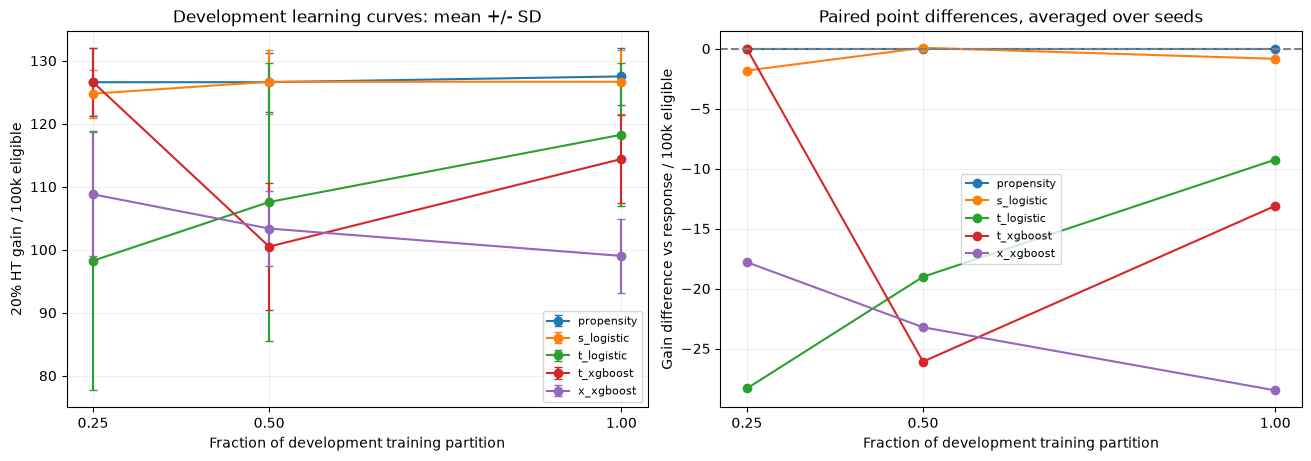

X-Learner 胜过 response 的开发配置数: 0 / 12
注意：25% 规模 T-XGBoost 和 response 指标相等；选择频率含固定候选顺序的 tie-break，不能当作获胜证据。


In [3]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
for name in ['propensity','s_logistic','t_logistic','t_xgboost','x_xgboost']:
    a=agg[(agg.split_method=='row_stratified') & (agg.policy==name)].sort_values('training_fraction')
    axes[0].errorbar(a.training_fraction,a.incremental_per_100k_mean,yerr=a.incremental_per_100k_std,marker='o',capsize=3,label=name)
    axes[1].plot(a.training_fraction,a.vs_propensity_per_100k_mean,'o-',label=name)
axes[0].set(title='Development learning curves: mean +/- SD',ylabel='20% HT gain / 100k eligible')
axes[1].axhline(0,color='gray',ls='--')
axes[1].set(title='Paired point differences, averaged over seeds',ylabel='Gain difference vs response / 100k eligible')
for ax in axes:
    ax.set_xlabel('Fraction of development training partition');ax.set_xticks([.25,.5,1]);ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.savefig(FIG/'stability_learning_curves.png',dpi=160);plt.show()
x=long[long.policy=='x_xgboost']
print('X-Learner 胜过 response 的开发配置数:',int((x.vs_propensity_per_100k>0).sum()),'/',len(x))
print('注意：25% 规模 T-XGBoost 和 response 指标相等；选择频率含固定候选顺序的 tie-break，不能当作获胜证据。')

## 冻结预测的 v2 指标与配对区间

增加了传统 plug-in AUUC、HT AUUC、两者中心化面积和传统 Qini 区间。只有已有测试预测被重算，未重新训练/选择；这不是一次新独立测试。

相对于 response 的区间包含 0 就不能宣称显著优于它。这些是固定模型、固定分配概率、给定臂样本量下的逐项区间，没有纳入训练和选择不确定性，也不是多个指标的同时区间。

,policy,n,auuc_ht,qini_ht,ate_ht,auuc_plugin,auuc_plugin_centered,qini_score_traditional
0,s_logistic,200000,0.001196,0.000580,0.001231,0.001132,0.000516,0.000444
1,t_logistic,200000,0.001210,0.000595,0.001231,0.001148,0.000533,0.000458
2,t_xgboost,200000,0.000972,0.000357,0.001231,0.000912,0.000296,0.000256
3,x_xgboost,200000,0.001099,0.000484,0.001231,0.001057,0.000441,0.000379
4,propensity,200000,0.001198,0.000583,0.001231,0.001137,0.000522,0.000448


,policy,metric,estimate,ci_low,ci_high,vs_propensity,vs_propensity_ci_low,vs_propensity_ci_high,bootstrap
0,s_logistic,auuc_ht,0.001196,0.000637,0.001650,-0.000003,-0.000023,0.000017,200
1,s_logistic,qini_ht,0.000580,0.000302,0.000808,-0.000003,-0.000023,0.000017,200
2,s_logistic,auuc_plugin,0.001132,0.000565,0.001590,-0.000006,-0.000030,0.000016,200
3,s_logistic,auuc_plugin_centered,0.000516,0.000238,0.000749,-0.000006,-0.000030,0.000016,200
4,s_logistic,qini_score_traditional,0.000444,0.000204,0.000644,-0.000004,-0.000025,0.000014,200
5,t_logistic,auuc_ht,0.001210,0.000720,0.001611,0.000012,-0.000130,0.000183,200
6,t_logistic,qini_ht,0.000595,0.000372,0.000804,0.000012,-0.000130,0.000183,200
7,t_logistic,auuc_plugin,0.001148,0.000649,0.001574,0.000011,-0.000128,0.000181,200
8,t_logistic,auuc_plugin_centered,0.000533,0.000314,0.000745,0.000011,-0.000128,0.000181,200
9,t_logistic,qini_score_traditional,0.000458,0.000270,0.000641,0.000010,-0.000108,0.000155,200


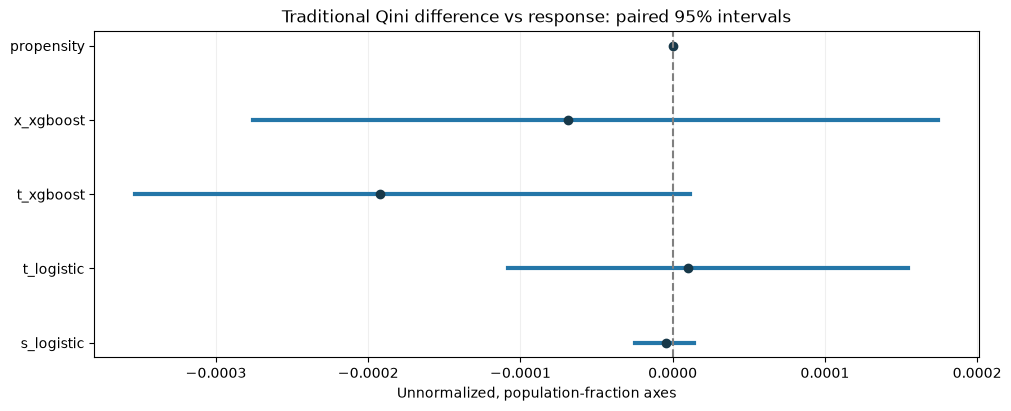

In [4]:
MET=result_directory('metrics_v2', ROOT)
display(pd.read_csv(MET/'ranking.csv'))
intervals=pd.read_csv(MET/'ranking_intervals.csv')
display(intervals)
chosen=intervals[intervals.metric=='qini_score_traditional'].copy()
fig,ax=plt.subplots(figsize=(10,4),layout='constrained')
# Use lines for percentile endpoints; intervals need not contain the point estimate.
for i,row in enumerate(chosen.itertuples()):
    ax.plot([row.vs_propensity_ci_low,row.vs_propensity_ci_high],[i,i],color='#2476a8',lw=3)
    ax.plot(row.vs_propensity,i,'o',color='#173849')
ax.axvline(0,color='gray',ls='--');ax.set_yticks(range(len(chosen)),chosen.policy)
ax.set(title='Traditional Qini difference vs response: paired 95% intervals',xlabel='Unnormalized, population-fraction axes')
ax.grid(axis='x',alpha=.2);fig.savefig(FIG/'qini_paired_intervals.png',dpi=160);plt.show()

## SQL：派生实验表、主键连接、条件聚合与窗口函数

这是从公开 CSV 派生的 SQLite 表；`row_id` 是原始行号，不是真实用户 ID，也没有伪造事件时间。SQL 演示唯一键/外键约束、1:1 完整连接、两臂 CVR、十分位分桶与预算排名。平分优先级与 Python 相同，便于逐项核对 HT。

完整查询在 `artifacts/sql_audit_v1/queries.sql`。

In [5]:
SQL=result_directory('sql_audit_v1', ROOT)
display(pd.read_csv(SQL/'join_integrity.csv'))
display(pd.read_csv(SQL/'cvr.csv'))
display(pd.read_csv(SQL/'policy_values.csv'))
display(pd.read_csv(SQL/'score_bins.csv').head(12))
print((SQL/'queries.sql').read_text())

,table_pair,policy,assignment_rows,outcome_rows,joined_rows,missing_outcomes,orphan_outcomes,score_rows,distinct_score_rows,missing_scores
0,assignment_outcome,NaN,200000.0,200000.0,200000,0.0,0.0,NaN,NaN,NaN
1,assignment_outcome_scores,s_logistic,NaN,NaN,200000,NaN,NaN,200000.0,200000.0,0.0
2,assignment_outcome_scores,t_logistic,NaN,NaN,200000,NaN,NaN,200000.0,200000.0,0.0
3,assignment_outcome_scores,t_xgboost,NaN,NaN,200000,NaN,NaN,200000.0,200000.0,0.0
4,assignment_outcome_scores,x_xgboost,NaN,NaN,200000,NaN,NaN,200000.0,200000.0,0.0
5,assignment_outcome_scores,propensity,NaN,NaN,200000,NaN,NaN,200000.0,200000.0,0.0


,n,n_treatment,n_control,responses_treatment,responses_control,cvr_treatment,cvr_control,difference_in_means,ate_ht
0,200000,170082,29918,522,55,0.003069,0.001838,0.001231,0.001231


,policy,budget,n_eligible,n_selected,selected_fraction,sql_incremental_per_100k,python_incremental_per_100k,sql_minus_python,vs_random_per_100k,selected_on_validation
0,random,0.2,200000,40000,0.2,24.614993,24.614993,0.000000e+00,0.000000,False
1,s_logistic,0.2,200000,40000,0.2,123.324666,123.324666,9.521273e-13,98.709673,False
2,t_logistic,0.2,200000,40000,0.2,126.328883,126.328883,8.384404e-13,101.713890,False
3,t_xgboost,0.2,200000,40000,0.2,95.352684,95.352684,6.110668e-13,70.737691,False
4,x_xgboost,0.2,200000,40000,0.2,110.115936,110.115936,5.826450e-13,85.500942,False
5,propensity,0.2,200000,40000,0.2,117.227679,117.227679,7.531753e-13,92.612686,True


,policy,score_bin,n,first_rank,last_rank,mean_score,min_score,max_score,n_treatment,n_control,responses_treatment,responses_control,cvr_treatment,cvr_control,observed_uplift,incremental_per_100k_eligible
0,s_logistic,1,20000,1,20000,0.008981,0.001116,0.138409,17275,2725,461,47,0.026686,0.017248,0.009438,113.949668
1,s_logistic,2,20000,20001,40000,0.000675,0.000445,0.001116,17095,2905,33,3,0.001930,0.001033,0.000898,9.374998
2,s_logistic,3,20000,40001,60000,0.000362,0.000302,0.000445,16972,3028,8,0,0.000471,0.000000,0.000471,4.703614
3,s_logistic,4,20000,60001,80000,0.000264,0.000233,0.000302,16948,3052,5,3,0.000295,0.000983,-0.000688,-7.087650
4,s_logistic,5,20000,80001,100000,0.000211,0.000194,0.000233,16973,3027,4,1,0.000236,0.000330,-0.000095,-0.990663
5,s_logistic,6,20000,100001,120000,0.000181,0.000170,0.000194,17049,2951,2,0,0.000117,0.000000,0.000117,1.175903
6,s_logistic,7,20000,120001,140000,0.000162,0.000154,0.000170,16890,3110,1,1,0.000059,0.000322,-0.000262,-2.754518
7,s_logistic,8,20000,140001,160000,0.000147,0.000139,0.000154,16938,3062,5,0,0.000295,0.000000,0.000295,2.939758
8,s_logistic,9,20000,160001,180000,0.000131,0.000123,0.000139,16974,3026,0,0,0.000000,0.000000,0.000000,0.000000
9,s_logistic,10,20000,180001,200000,0.000106,0.000045,0.000123,16968,3032,3,0,0.000177,0.000000,0.000177,1.763855


-- SQLite evidence: normalized derived tables; no synthetic user IDs.
-- Bind parameters: policy (name), e (frozen assignment probability),
-- n (all eligible test rows), k=floor(budget*n+1e-12), n_bins.
-- Scores are loaded one policy at a time with executemany.
-- tie_priority = NumPy default_rng(seed).random(n), aligned to input order.
-- NTILE bin 1 contains the highest scores. NULL denotes a missing arm.

-- schema
PRAGMA foreign_keys = ON;
PRAGMA temp_store = MEMORY;
CREATE TABLE assignment (
    row_id INTEGER PRIMARY KEY,
    input_position INTEGER NOT NULL UNIQUE,
    treatment INTEGER NOT NULL CHECK (treatment IN (0, 1))
);
CREATE TABLE outcome (
    row_id INTEGER PRIMARY KEY REFERENCES assignment(row_id),
    response INTEGER NOT NULL CHECK (response IN (0, 1))
);
CREATE TABLE policy_scores (
    policy TEXT NOT NULL,
    row_id INTEGER NOT NULL REFERENCES assignment(row_id),
    score REAL NOT NULL,
    tie_priority REAL NOT NULL,
    PRIMARY KEY (policy, row_id)
);

-- as

## 上线前决策：需要多少样本？在什么成本假设下才值得？

以下是**假设场景**，不是 Criteo 的真实收入、成本或线上 CVR。

两臂均覆盖各自入组人群的 20%，按全部入组人群比较策略 CVR。假设基线策略 $p_B=0.003$、要检出 $\delta=0.0003$，双侧 5%、80% 功效。样本量分母不是被触达的 20%；覆盖率也不能直接拿来除 MDE。

净增价值 = 估计增量转化 × 假设每次转化贡献毛利 − 接触人数 × 假设单次成本。等预算且单位成本相同的两策略比较中，成本项相消。

In [6]:
from criteo_uplift.planning import plan_policy_ab, cost_value_scenario
plans=pd.DataFrame([plan_policy_ab(.003,d) for d in [.00015,.0003,.0006]])
display(plans)
RUN=result_directory('conversion_1000000_seed42', ROOT)
pd_policy=pd.read_csv(RUN/'test_policies.csv')
selection=json.loads((RUN/'selection.json').read_text())
row=pd_policy[(pd_policy.policy==selection['selected_policy']) & np.isclose(pd_policy.budget,.2)].iloc[0]
scenarios=[]
for value in [1.,5.,10.]:
    for cost in [.001,.01,.05]:
        scenarios.append(cost_value_scenario(float(row.incremental_per_100k),budget=.2,value_per_conversion=value,contact_cost=cost,
                                            ci_low=float(row.ci_low),ci_high=float(row.ci_high)))
display(pd.DataFrame(scenarios))
print('单次接触盈亏平衡成本 = 增量转化 × 假设价值 / 接触人数；负值表示即使零成本也无正收益。')

,p0_assumed,p1_assumed,absolute_mde,relative_mde,alpha_two_sided,target_power,allocation_ratio_A_over_B,n_policy_B,n_policy_A,n_total,contact_fraction_each_policy,contacts_B,contacts_A,approximate_achieved_power,assumption
0,0.003,0.00315,0.00015,0.05,0.05,0.8,1.0,2138763,2138763,4277526,0.2,427752,427752,0.800001,Hypothetical policy CVRs on all eligible users...
1,0.003,0.00330,0.00030,0.10,0.05,0.8,1.0,547690,547690,1095380,0.2,109538,109538,0.800001,Hypothetical policy CVRs on all eligible users...
2,0.003,0.00360,0.00060,0.20,0.05,0.8,1.0,143421,143421,286842,0.2,28684,28684,0.800003,Hypothetical policy CVRs on all eligible users...


,incremental_per_100k,eligible_n,budget,contacts,value_per_conversion_assumed,contact_cost_assumed,incremental_conversions,gross_incremental_value,contact_cost_total,net_incremental_value,net_ci_low_conditional,net_ci_high_conditional,break_even_contact_cost,assumption
0,117.227679,100000,0.2,20000,1.0,0.001,117.227679,117.227679,20.0,97.227679,44.092311,146.214162,0.005861,"Hypothetical constant value/cost, fixed effect..."
1,117.227679,100000,0.2,20000,1.0,0.010,117.227679,117.227679,200.0,-82.772321,-135.907689,-33.785838,0.005861,"Hypothetical constant value/cost, fixed effect..."
2,117.227679,100000,0.2,20000,1.0,0.050,117.227679,117.227679,1000.0,-882.772321,-935.907689,-833.785838,0.005861,"Hypothetical constant value/cost, fixed effect..."
3,117.227679,100000,0.2,20000,5.0,0.001,117.227679,586.138394,20.0,566.138394,300.461555,811.070810,0.029307,"Hypothetical constant value/cost, fixed effect..."
4,117.227679,100000,0.2,20000,5.0,0.010,117.227679,586.138394,200.0,386.138394,120.461555,631.070810,0.029307,"Hypothetical constant value/cost, fixed effect..."
5,117.227679,100000,0.2,20000,5.0,0.050,117.227679,586.138394,1000.0,-413.861606,-679.538445,-168.929190,0.029307,"Hypothetical constant value/cost, fixed effect..."
6,117.227679,100000,0.2,20000,10.0,0.001,117.227679,1172.276788,20.0,1152.276788,620.923109,1642.141620,0.058614,"Hypothetical constant value/cost, fixed effect..."
7,117.227679,100000,0.2,20000,10.0,0.010,117.227679,1172.276788,200.0,972.276788,440.923109,1462.141620,0.058614,"Hypothetical constant value/cost, fixed effect..."
8,117.227679,100000,0.2,20000,10.0,0.050,117.227679,1172.276788,1000.0,172.276788,-359.076891,662.141620,0.058614,"Hypothetical constant value/cost, fixed effect..."


单次接触盈亏平衡成本 = 增量转化 × 假设价值 / 接触人数；负值表示即使零成本也无正收益。


## 当前可辩护的结论

1. 公共基准上，冻结的 response 策略在 20% 预算下高于解析随机策略；这不是线上收入增长。
2. S/T/X 已实装，复杂 X 并未优于强 response 基线；多次开发切分也未观察到反转。报告负结果是项目的一部分。
3. 少数臂事件数有限，特征匿名且用户/时间信息缺失。当前学习曲线不能单独证明“扩样就会解决”，尚未运行 500 万/全量模型或线上实验。
4. 下一步若有业务机会，冻结策略、候选池、转化窗口、同预算口径和停止规则，按真实用户随机开展策略 A/B；观察全部入组用户的转化与成本护栏。

面试复盘见 `因果推断理论/8.项目复盘与面试.md`。